# Import Library

In [1]:
from google.colab import files

uploaded = files.upload()

Saving online_shoppers_intention.csv to online_shoppers_intention.csv


In [2]:
import os

print(os.listdir())

['.config', 'online_shoppers_intention.csv', 'sample_data']


In [3]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# Ignore unnecessary warnings
import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:
df = pd.read_csv("online_shoppers_intention.csv")

print("Dataset loaded successfully.")

Dataset loaded successfully.


# Inspect the dataset

In [5]:
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [6]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 12330
Number of columns: 18


In [7]:
print(df.columns.tolist())

['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


# Check Missing Value

In [10]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64


In [11]:
print(df.isnull().sum()[df.isnull().sum() > 0])

Series([], dtype: int64)


In [12]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


# Check and remove duplicate records

In [13]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 125


In [14]:
df_cleaned = df.drop_duplicates().copy()

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_cleaned.shape)

Original dataset shape: (12330, 18)
Cleaned dataset shape: (12205, 18)


In [15]:
df_cleaned.reset_index(drop=True, inplace=True)

In [16]:
print("Remaining duplicates:", df_cleaned.duplicated().sum())

Remaining duplicates: 0


# Check the unique values

In [17]:
for column in df_cleaned.columns:
    print("\nColumn:", column)
    print(df_cleaned[column].unique()[:20])


Column: Administrative
[ 0  1  2  4 12  3 10  6  5  9  8 16 13 11  7 18 14 17 19 15]

Column: Administrative_Duration
[   0.           53.           64.6           6.           18.
    9.           56.           16.          279.4166667    87.83333333
   44.         1005.666667     36.           18.33333333   61.
   31.           58.5         326.25         22.          462.        ]

Column: Informational
[ 0  1  2  4 16  5  3 14  6 12  7  9 10  8 11 24 13]

Column: Informational_Duration
[   0.         120.          16.          94.          93.
   75.          19.          22.        1210.397619   153.
   48.5         51.           3.         144.         125.
  127.         261.         306.3333333   84.         740.       ]

Column: ProductRelated
[ 1  2 10 19  0  3 16  7  6 23 13 20  8  5 32  4 45 14 52  9]

Column: ProductRelated_Duration
[0.00000000e+00 6.40000000e+01 2.66666667e+00 6.27500000e+02
 1.54216667e+02 3.70000000e+01 7.38000000e+02 3.95000000e+02
 4.07750000e+02 2.8

In [18]:
print("Months:", df_cleaned["Month"].unique())
print("Visitor types:", df_cleaned["VisitorType"].unique())
print("Weekend:", df_cleaned["Weekend"].unique())
print("Revenue:", df_cleaned["Revenue"].unique())

Months: ['Feb' 'Mar' 'May' 'Oct' 'June' 'Jul' 'Aug' 'Nov' 'Sep' 'Dec']
Visitor types: ['Returning_Visitor' 'New_Visitor' 'Other']
Weekend: [False  True]
Revenue: [False  True]


# Correct the data types

In [19]:
categorical_columns = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

for column in categorical_columns:
    df_cleaned[column] = df_cleaned[column].astype("category")

In [20]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12205 entries, 0 to 12204
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   Administrative           12205 non-null  int64   
 1   Administrative_Duration  12205 non-null  float64 
 2   Informational            12205 non-null  int64   
 3   Informational_Duration   12205 non-null  float64 
 4   ProductRelated           12205 non-null  int64   
 5   ProductRelated_Duration  12205 non-null  float64 
 6   BounceRates              12205 non-null  float64 
 7   ExitRates                12205 non-null  float64 
 8   PageValues               12205 non-null  float64 
 9   SpecialDay               12205 non-null  float64 
 10  Month                    12205 non-null  category
 11  OperatingSystems         12205 non-null  category
 12  Browser                  12205 non-null  category
 13  Region                   12205 non-null  category
 14  Traffi

# Examine the target variable

In [21]:
revenue_counts = df_cleaned["Revenue"].value_counts()

print(revenue_counts)

Revenue
False    10297
True      1908
Name: count, dtype: int64


In [22]:
revenue_percentage = (
    df_cleaned["Revenue"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(revenue_percentage)

Revenue
False    84.37
True     15.63
Name: proportion, dtype: float64


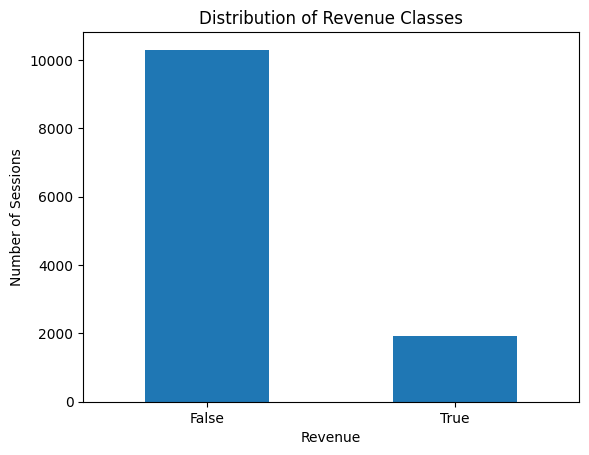

In [23]:
df_cleaned["Revenue"].value_counts().plot(kind="bar")

plt.title("Distribution of Revenue Classes")
plt.xlabel("Revenue")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=0)
plt.show()

# Perform basic exploratory data analysis

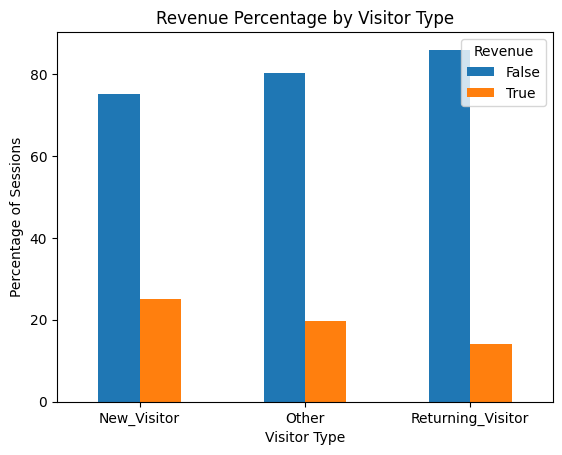

In [24]:
visitor_revenue = pd.crosstab(
    df_cleaned["VisitorType"],
    df_cleaned["Revenue"],
    normalize="index"
) * 100

visitor_revenue.plot(kind="bar")

plt.title("Revenue Percentage by Visitor Type")
plt.xlabel("Visitor Type")
plt.ylabel("Percentage of Sessions")
plt.xticks(rotation=0)
plt.legend(title="Revenue")
plt.show()

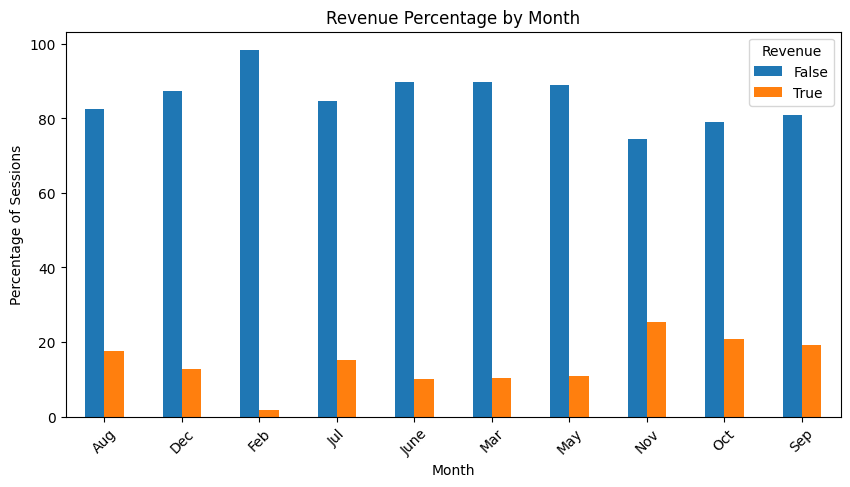

In [25]:
month_revenue = pd.crosstab(
    df_cleaned["Month"],
    df_cleaned["Revenue"],
    normalize="index"
) * 100

month_revenue.plot(kind="bar", figsize=(10, 5))

plt.title("Revenue Percentage by Month")
plt.xlabel("Month")
plt.ylabel("Percentage of Sessions")
plt.xticks(rotation=45)
plt.legend(title="Revenue")
plt.show()

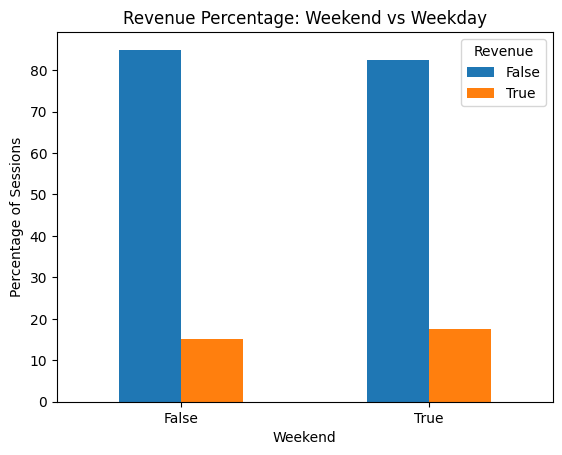

In [26]:
weekend_revenue = pd.crosstab(
    df_cleaned["Weekend"],
    df_cleaned["Revenue"],
    normalize="index"
) * 100

weekend_revenue.plot(kind="bar")

plt.title("Revenue Percentage: Weekend vs Weekday")
plt.xlabel("Weekend")
plt.ylabel("Percentage of Sessions")
plt.xticks(rotation=0)
plt.legend(title="Revenue")
plt.show()

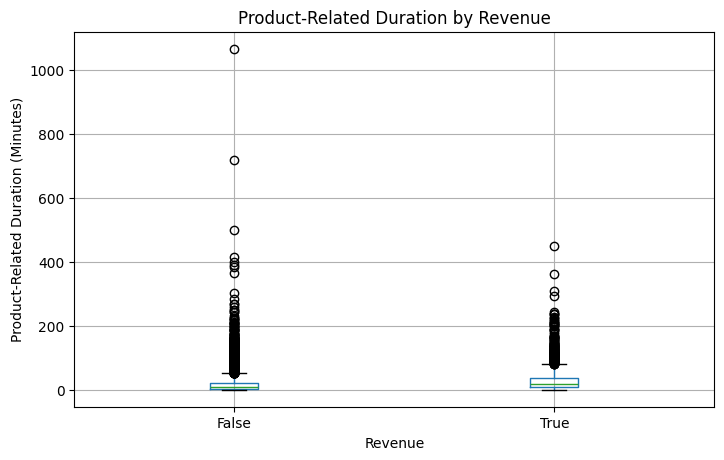

In [27]:
df_cleaned["ProductRelated_Duration_Minutes"] = (
    df_cleaned["ProductRelated_Duration"] / 60
)

df_cleaned.boxplot(
    column="ProductRelated_Duration_Minutes",
    by="Revenue",
    figsize=(8, 5)
)

plt.title("Product-Related Duration by Revenue")
plt.suptitle("")
plt.xlabel("Revenue")
plt.ylabel("Product-Related Duration (Minutes)")
plt.show()

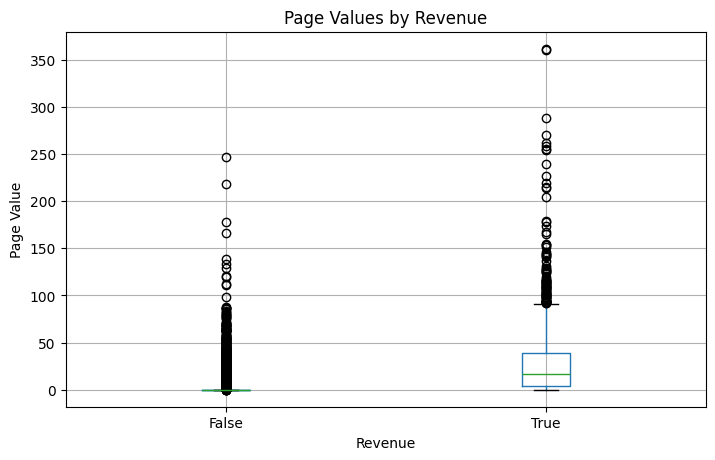

In [28]:
df_cleaned.boxplot(
    column="PageValues",
    by="Revenue",
    figsize=(8, 5)
)

plt.title("Page Values by Revenue")
plt.suptitle("")
plt.xlabel("Revenue")
plt.ylabel("Page Value")
plt.show()

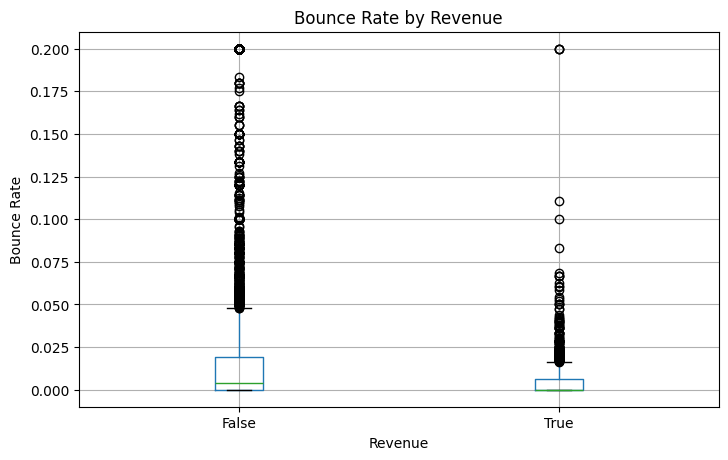

In [29]:
df_cleaned.boxplot(
    column="BounceRates",
    by="Revenue",
    figsize=(8, 5)
)

plt.title("Bounce Rate by Revenue")
plt.suptitle("")
plt.xlabel("Revenue")
plt.ylabel("Bounce Rate")
plt.show()

# Separate features and target

In [30]:
X = df_cleaned.drop("Revenue", axis=1)

y = df_cleaned["Revenue"].astype(int)

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

Feature dataset shape: (12205, 18)
Target dataset shape: (12205,)


In [31]:
print(y.value_counts())

Revenue
0    10297
1     1908
Name: count, dtype: int64


# Identify numerical and categorical columns

In [32]:
categorical_features = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

numerical_features = [
    column for column in X.columns
    if column not in categorical_features
]

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'ProductRelated_Duration_Minutes']

Categorical features:
['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']


# Split the data into training and testing sets

In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (9764, 18)
Testing features: (2441, 18)
Training target: (9764,)
Testing target: (2441,)


# Build the preprocessing pipeline

In [34]:
numerical_transformer = Pipeline(
    steps=[
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


# Choose the machine learning models

In [35]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "K-Nearest Neighbours": KNeighborsClassifier(
        n_neighbors=7
    )
}

print("Models prepared:")
for model_name in models:
    print("-", model_name)

Models prepared:
- Logistic Regression
- Decision Tree
- Random Forest
- K-Nearest Neighbours


# Train and evaluate all models

In [36]:
results = []
trained_models = {}

for model_name, model in models.items():

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", model)
        ]
    )

    # Train the model
    pipeline.fit(X_train, y_train)

    # Make predictions
    y_pred = pipeline.predict(X_test)

    # Obtain prediction probabilities
    if hasattr(pipeline.named_steps["classifier"], "predict_proba"):
        y_probability = pipeline.predict_proba(X_test)[:, 1]
    else:
        y_probability = None

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    if y_probability is not None:
        roc_auc = roc_auc_score(y_test, y_probability)
    else:
        roc_auc = np.nan

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": roc_auc
    })

    trained_models[model_name] = pipeline

    print("=" * 60)
    print(model_name)
    print("=" * 60)
    print(classification_report(y_test, y_pred, digits=4))

Logistic Regression
              precision    recall  f1-score   support

           0     0.9576    0.8558    0.9038      2059
           1     0.5058    0.7958    0.6185       382

    accuracy                         0.8464      2441
   macro avg     0.7317    0.8258    0.7612      2441
weighted avg     0.8869    0.8464    0.8592      2441

Decision Tree
              precision    recall  f1-score   support

           0     0.9531    0.8684    0.9088      2059
           1     0.5204    0.7696    0.6209       382

    accuracy                         0.8529      2441
   macro avg     0.7367    0.8190    0.7648      2441
weighted avg     0.8854    0.8529    0.8637      2441

Random Forest
              precision    recall  f1-score   support

           0     0.9178    0.9650    0.9408      2059
           1     0.7391    0.5340    0.6201       382

    accuracy                         0.8976      2441
   macro avg     0.8285    0.7495    0.7804      2441
weighted avg     0.8898   

# Create the model comparison table

In [37]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

results_df.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Decision Tree,0.8529,0.5204,0.7696,0.6209,0.8745
1,Random Forest,0.8976,0.7391,0.5340,0.6201,0.9230
2,Logistic Regression,0.8464,0.5058,0.7958,0.6185,0.9097
3,K-Nearest Neighbours,0.8755,0.6757,0.3927,0.4967,0.8152


In [38]:
results_percentage = results_df.copy()

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

results_percentage[metric_columns] = (
    results_percentage[metric_columns] * 100
).round(2)

results_percentage

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Decision Tree,85.29,52.04,76.96,62.09,87.45
1,Random Forest,89.76,73.91,53.40,62.01,92.30
2,Logistic Regression,84.64,50.58,79.58,61.85,90.97
3,K-Nearest Neighbours,87.55,67.57,39.27,49.67,81.52


# Plot the model comparison

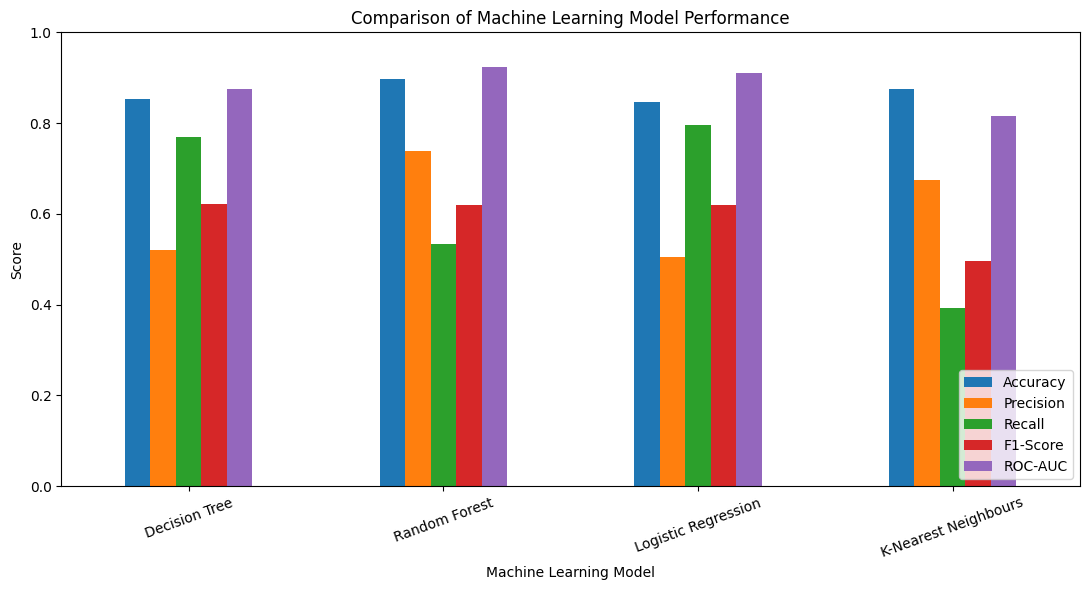

In [39]:
results_plot = results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
]

results_plot.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Comparison of Machine Learning Model Performance")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# Display confusion matrices

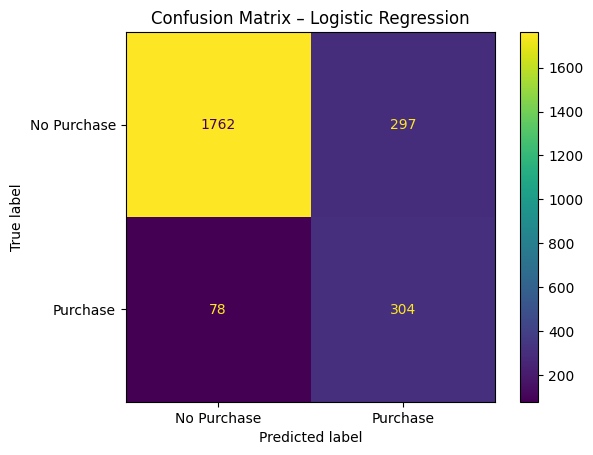

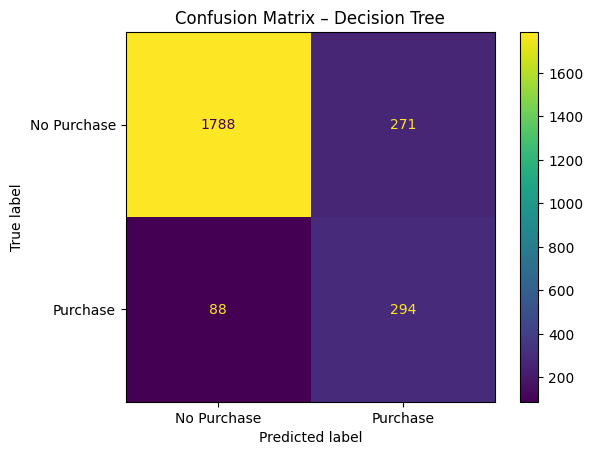

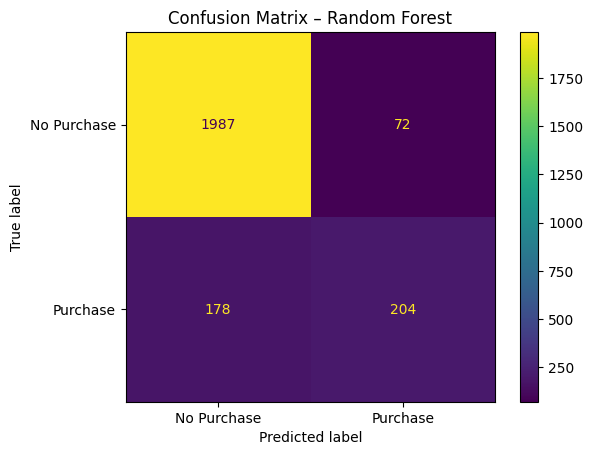

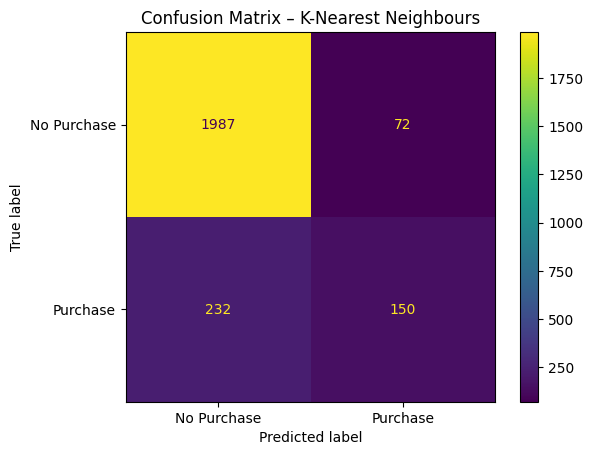

In [40]:
for model_name, pipeline in trained_models.items():

    y_pred = pipeline.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["No Purchase", "Purchase"],
        values_format="d"
    )

    plt.title(f"Confusion Matrix – {model_name}")
    plt.show()

# Plot ROC curves

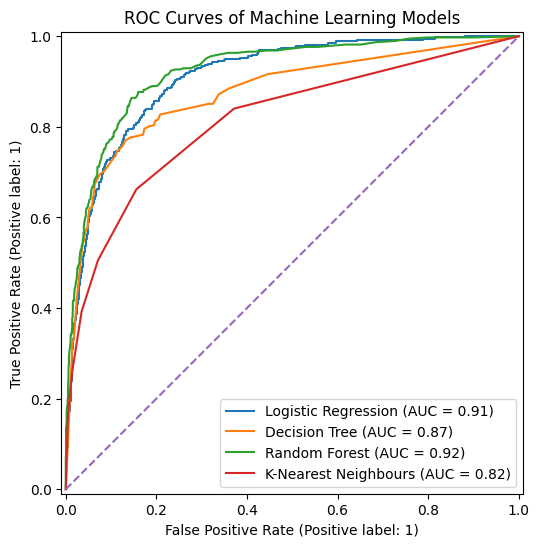

In [41]:
plt.figure(figsize=(8, 6))

ax = plt.gca()

for model_name, pipeline in trained_models.items():

    classifier = pipeline.named_steps["classifier"]

    if hasattr(classifier, "predict_proba"):
        RocCurveDisplay.from_estimator(
            pipeline,
            X_test,
            y_test,
            name=model_name,
            ax=ax
        )

plt.title("ROC Curves of Machine Learning Models")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.show()

# Identify the best model

In [42]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best model based on F1-score:", best_model_name)

Best model based on F1-score: Decision Tree


In [43]:
results_df.iloc[0]

,0
Model,Decision Tree
Accuracy,0.852929
Precision,0.520354
Recall,0.769634
F1-Score,0.620908
ROC-AUC,0.874461


# Display the best model’s classification report

In [44]:
best_predictions = best_model.predict(X_test)

print("Best model:", best_model_name)
print()
print(classification_report(
    y_test,
    best_predictions,
    target_names=["No Purchase", "Purchase"],
    digits=4
))

Best model: Decision Tree

              precision    recall  f1-score   support

 No Purchase     0.9531    0.8684    0.9088      2059
    Purchase     0.5204    0.7696    0.6209       382

    accuracy                         0.8529      2441
   macro avg     0.7367    0.8190    0.7648      2441
weighted avg     0.8854    0.8529    0.8637      2441



# Feature importance

In [45]:
random_forest_pipeline = trained_models["Random Forest"]

rf_preprocessor = random_forest_pipeline.named_steps["preprocessor"]
rf_classifier = random_forest_pipeline.named_steps["classifier"]

feature_names = rf_preprocessor.get_feature_names_out()
feature_importances = rf_classifier.feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importances
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

feature_importance_df.head(15)

,Feature,Importance
0,num__PageValues,0.326939
1,num__ExitRates,0.078243
2,num__ProductRelated_Duration,0.068297
3,num__ProductRelated_Duration_Minutes,0.067666
4,num__ProductRelated,0.059328
5,num__BounceRates,0.049441
6,num__Administrative_Duration,0.043637
7,num__Administrative,0.037636
8,cat__Month_Nov,0.024731
9,num__Informational_Duration,0.018953


In [46]:
feature_importance_df["Feature"] = (
    feature_importance_df["Feature"]
    .str.replace("num__", "", regex=False)
    .str.replace("cat__", "", regex=False)
)

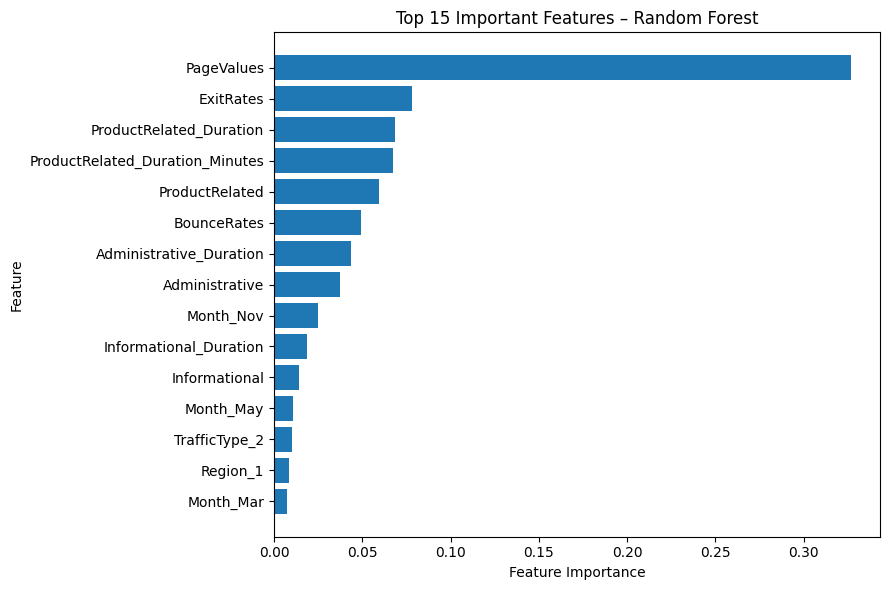

In [47]:
top_features = feature_importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(9, 6))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Important Features – Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# Optional SVM model

In [48]:
svm_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            SVC(
                kernel="rbf",
                probability=True,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

svm_pipeline.fit(X_train, y_train)

svm_predictions = svm_pipeline.predict(X_test)
svm_probabilities = svm_pipeline.predict_proba(X_test)[:, 1]

print(classification_report(
    y_test,
    svm_predictions,
    digits=4
))

print("Accuracy:", accuracy_score(y_test, svm_predictions))
print("Precision:", precision_score(y_test, svm_predictions))
print("Recall:", recall_score(y_test, svm_predictions))
print("F1-score:", f1_score(y_test, svm_predictions))
print("ROC-AUC:", roc_auc_score(y_test, svm_probabilities))

              precision    recall  f1-score   support

           0     0.9536    0.8893    0.9203      2059
           1     0.5624    0.7670    0.6489       382

    accuracy                         0.8701      2441
   macro avg     0.7580    0.8281    0.7846      2441
weighted avg     0.8924    0.8701    0.8779      2441

Accuracy: 0.8701351904956984
Precision: 0.5623800383877159
Recall: 0.7670157068062827
F1-score: 0.6489479512735327
ROC-AUC: 0.908957990586596


# Add predictions to the cleaned dataset

In [51]:
all_predictions = best_model.predict(X)

if hasattr(best_model.named_steps["classifier"], "predict_proba"):
    all_probabilities = best_model.predict_proba(X)[:, 1]
else:
    all_probabilities = np.nan

In [50]:
powerbi_df = df_cleaned.copy()

powerbi_df["ActualRevenue"] = powerbi_df["Revenue"].map({
    False: "No Purchase",
    True: "Purchase"
})

powerbi_df["PredictedRevenue"] = np.where(
    all_predictions == 1,
    "Purchase",
    "No Purchase"
)

powerbi_df["PurchaseProbability"] = all_probabilities

powerbi_df["PredictionCorrect"] = np.where(
    powerbi_df["Revenue"].astype(int) == all_predictions,
    "Correct",
    "Incorrect"
)

powerbi_df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,Region,TrafficType,VisitorType,Weekend,Revenue,ProductRelated_Duration_Minutes,ActualRevenue,PredictedRevenue,PurchaseProbability,PredictionCorrect
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,1,1,Returning_Visitor,False,False,0.000000,No Purchase,No Purchase,0.0,Correct
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,...,1,2,Returning_Visitor,False,False,1.066667,No Purchase,No Purchase,0.0,Correct
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,9,3,Returning_Visitor,False,False,0.000000,No Purchase,No Purchase,0.0,Correct
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,...,2,4,Returning_Visitor,False,False,0.044444,No Purchase,No Purchase,0.0,Correct
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,...,1,4,Returning_Visitor,True,False,10.458333,No Purchase,No Purchase,0.0,Correct


# Create helpful Power BI columns

In [52]:
powerbi_df.insert(
    0,
    "SessionID",
    range(1, len(powerbi_df) + 1)
)

In [53]:
powerbi_df["ProductRelatedDuration_Minutes"] = (
    powerbi_df["ProductRelated_Duration"] / 60
)

powerbi_df["AdministrativeDuration_Minutes"] = (
    powerbi_df["Administrative_Duration"] / 60
)

powerbi_df["InformationalDuration_Minutes"] = (
    powerbi_df["Informational_Duration"] / 60
)

In [54]:
powerbi_df["DayType"] = powerbi_df["Weekend"].map({
    True: "Weekend",
    False: "Weekday"
})

# Export the cleaned files

In [55]:
df_cleaned.to_csv(
    "cleaned_online_shoppers_data.csv",
    index=False
)

In [56]:
powerbi_df.to_csv(
    "online_shoppers_powerbi_data.csv",
    index=False
)

In [57]:
results_percentage.to_csv(
    "model_performance_results.csv",
    index=False
)

In [58]:
feature_importance_df.to_csv(
    "feature_importance_results.csv",
    index=False
)

In [59]:
from google.colab import files

files.download("cleaned_online_shoppers_data.csv")
files.download("online_shoppers_powerbi_data.csv")
files.download("model_performance_results.csv")
files.download("feature_importance_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>